In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import fspiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from kepler_utils import *
import batman_utils
from HItargets_utils import hi_planets_by_name, filter_loc, filter_lambda

looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected


In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
K2_141b = hi_planets_by_name("K2-141 b")

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from K2-141 data, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

In [3]:
# Albedo assumptions

# Geometric albedo in the optical from Zieba 2022 (Spitzer data are not able to constrain the albedo at 4.5 µm). This is likely an overestimate.
Ag = 0.28

# Assuming grey Lambertian reflectance. PROBABLY UNPHYSICAL!
A_B = 3 / 2 * Ag
# More physical would be:
# A_B = 0.1 # typical lava world (Essack 2020)
# A_B = q * f_red * Ag_opt # with q~0.6 (more realistic for e.g. moon, Mercury), and f_red a spectral correction factor.

# Model for band-integrated albedo in MIRI/LRS band (MIR)
# ASSUMPTION (!): Band-integrated albedo of rocky surface stays approx. const at A=0.1 (small reflected part) in MIR
A = 0.1

In [4]:
# Filter to be used
Instrument = "MIRI/F1280W"
lambda_range = filter_lambda(Instrument)
filter_path = filter_loc(Instrument)

## Full (thermal + reflected) phase curve

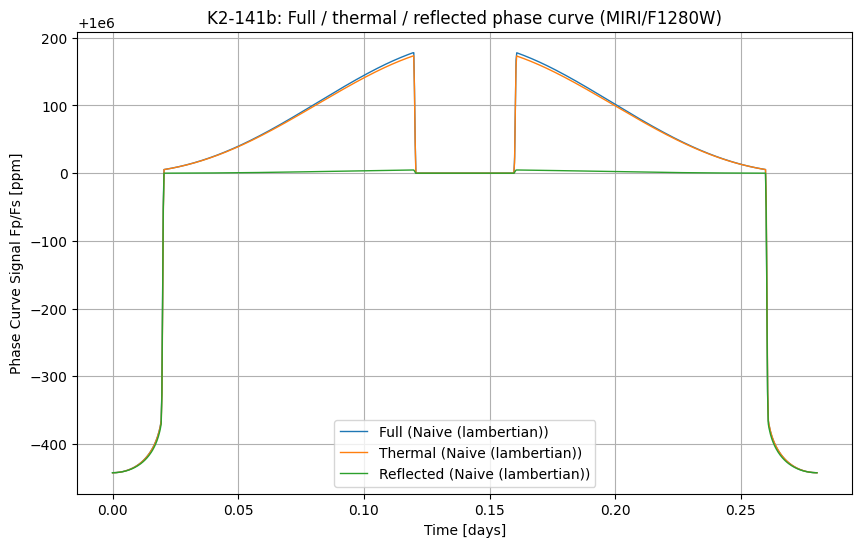

Naive (lambertian)     occultation depth:  full= 192.8  thermal= 187.5  reflected=   5.3  ppm


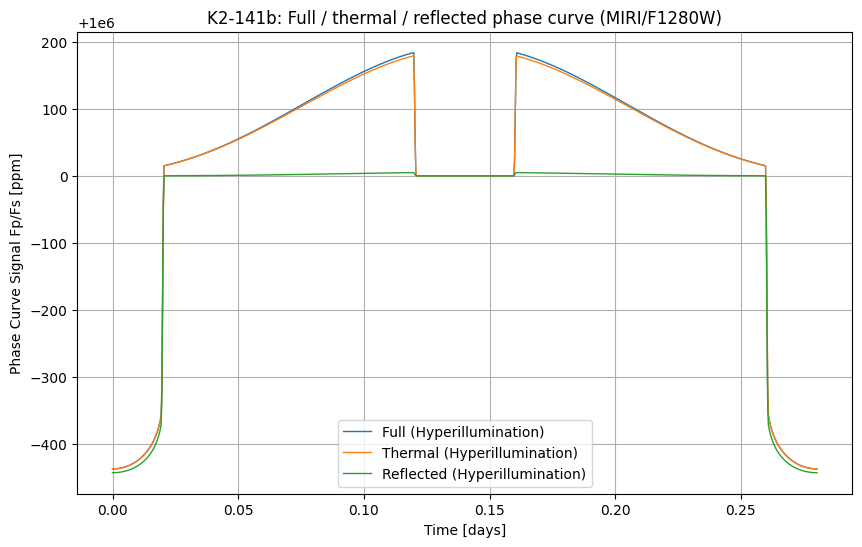

Hyperillumination      occultation depth:  full= 193.7  thermal= 188.4  reflected=   5.3  ppm


In [5]:
for model, mlabel in [("naive", "Naive (lambertian)"), ("hyperillum", "Hyperillumination")]:
    t_full,  full_pc,  fp_full     = full_PhaseCurve(K2_141b, lambda_range, u=u, A=A, A_B=A_B, filter_path=filter_path, insolation_model=model, u_B=u_B)
    t_therm, therm_pc, fp_therm, _ = thermal_PhaseCurve(K2_141b, lambda_range, u=u, A_B=A_B, filter_path=filter_path, insolation_model=model, u_B=u_B)
    t_refl,  refl_pc,  fp_refl     = reflected_PhaseCurve(K2_141b, u=u, A=A, insolation_model=model, u_B=u_B)
    
    plt.figure(figsize=(10, 6))
    plt.plot(t_full,  full_pc*1e6, color="C0", linewidth=1, label=f"Full ({mlabel})")
    plt.plot(t_therm, therm_pc*1e6, color="C1", linewidth=1, label=f"Thermal ({mlabel})")
    plt.plot(t_refl,  refl_pc*1e6, color="C2", linewidth=1, label=f"Reflected ({mlabel})")
    plt.xlabel("Time [days]")
    plt.ylabel(r"Phase Curve Signal Fp/Fs [ppm]")
    plt.title(f"K2-141b: Full / thermal / reflected phase curve ({Instrument})")
    plt.legend()
    plt.grid()
    plt.show()
    print(f"{mlabel:22s} occultation depth:  full={fp_full:6.1f}  thermal={fp_therm:6.1f}  reflected={fp_refl:6.1f}  ppm")


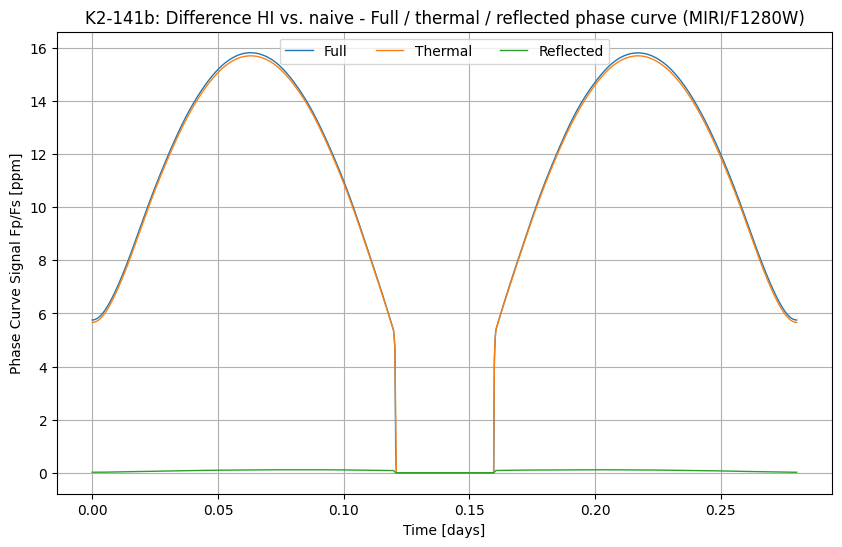

In [6]:
t_full1,  full_pc1,  fp_full1     = full_PhaseCurve(K2_141b, lambda_range, u=u, A=A, A_B=A_B, filter_path=filter_path, insolation_model="naive", u_B=u_B)
t_therm1, therm_pc1, fp_therm1, _ = thermal_PhaseCurve(K2_141b, lambda_range, u=u, A_B=A_B, filter_path=filter_path, insolation_model="naive", u_B=u_B)
t_refl1,  refl_pc1,  fp_refl1     = reflected_PhaseCurve(K2_141b, u=u, A=A, insolation_model="naive", u_B=u_B)
t_full2,  full_pc2,  fp_full2     = full_PhaseCurve(K2_141b, lambda_range, u=u, A=A, A_B=A_B, filter_path=filter_path, insolation_model="hyperillum", u_B=u_B)
t_therm2, therm_pc2, fp_therm2, _ = thermal_PhaseCurve(K2_141b, lambda_range, u=u, A_B=A_B, filter_path=filter_path, insolation_model="hyperillum", u_B=u_B)
t_refl2,  refl_pc2,  fp_refl2     = reflected_PhaseCurve(K2_141b, u=u, A=A, insolation_model="hyperillum", u_B=u_B)

plt.figure(figsize=(10, 6))
plt.plot(t_full1,  np.abs(full_pc1 - full_pc2)*1e6, color="C0", linewidth=1, label=f"Full")
plt.plot(t_therm1, np.abs(therm_pc1 - therm_pc2)*1e6, color="C1", linewidth=1, label=f"Thermal")
plt.plot(t_refl1,  np.abs(refl_pc1 - refl_pc2)*1e6, color="C2", linewidth=1, label=f"Reflected")
plt.xlabel("Time [days]")
plt.ylabel(r"Phase Curve Signal Fp/Fs [ppm]")
plt.title(f"K2-141b: Difference HI vs. naive - Full / thermal / reflected phase curve ({Instrument})")
plt.legend(ncol=3)
plt.grid()
plt.show()

## Full phase curve vs. albedo ($A = A_B$)

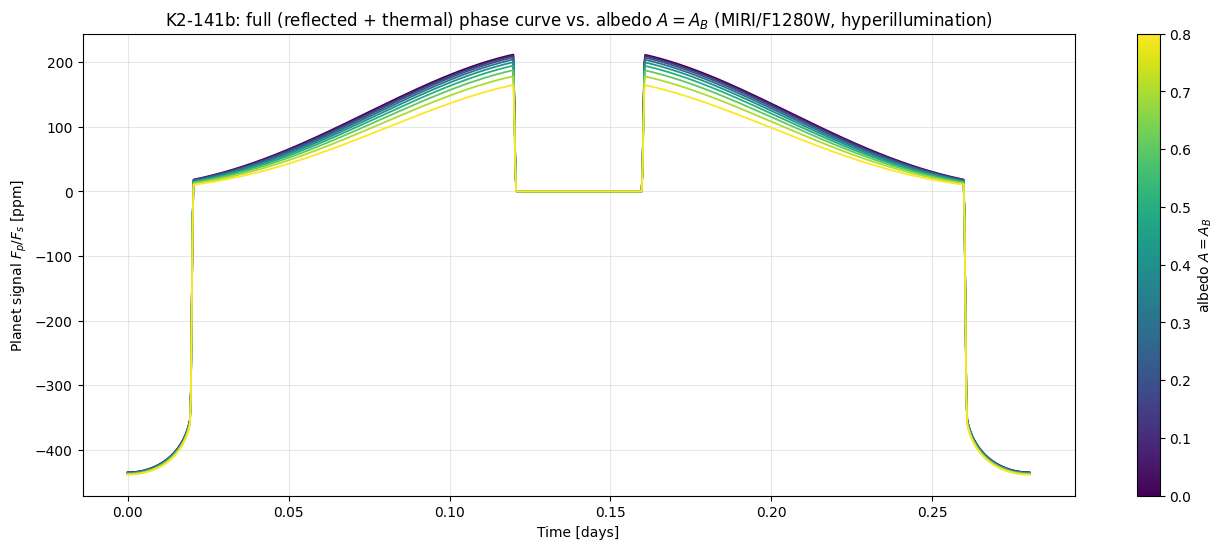

In [7]:
albedos = np.linspace(0.0, 0.8, 9)          # sweep A = A_B together (grey-Lambertian coupling)
cmap, norm = plt.cm.viridis, plt.Normalize(albedos.min(), albedos.max())

plt.figure(figsize=(16, 6))
for alb in albedos:
    t, pc, _ = full_PhaseCurve(K2_141b, lambda_range, u=u, A=alb, A_B=alb,
                               filter_path=filter_path, insolation_model="hyperillum", u_B=u_B)
    plt.plot(t, (pc - 1) * 1e6, color=cmap(norm(alb)), linewidth=1.3)   # (pc-1): planet signal, baseline 0
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm); sm.set_array([])
plt.colorbar(sm, ax=plt.gca(), label=r"albedo $A = A_B$")
plt.xlabel("Time [days]")
plt.ylabel(r"Planet signal $F_p/F_s$ [ppm]")
plt.title(f"K2-141b: full (reflected + thermal) phase curve vs. albedo $A=A_B$ ({Instrument}, hyperillumination)")
plt.grid(alpha=.3)
plt.show()

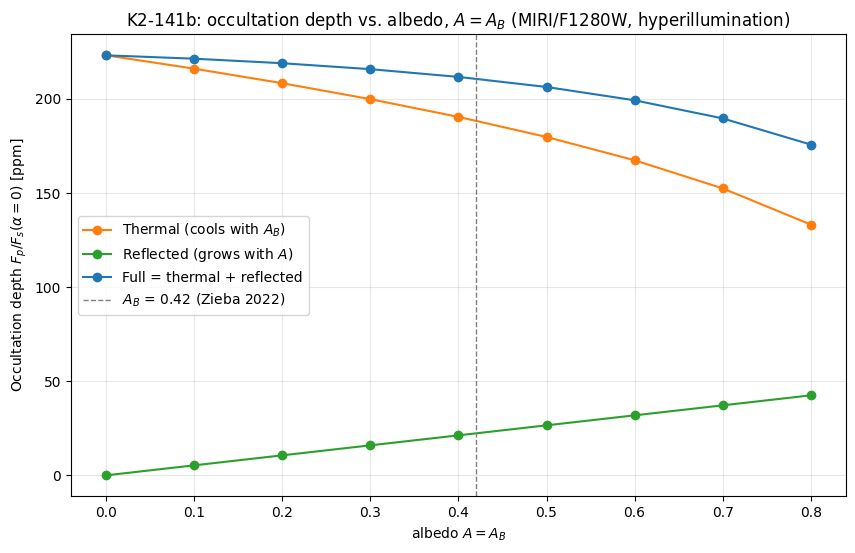

In [8]:
# Why the net effect is muted: occultation depth vs albedo, split into thermal (cools -> falls) and reflected (grows with A)
fp_therm, fp_refl = [], []
for alb in albedos:
    _, _, f_therm, _ = thermal_PhaseCurve(K2_141b, lambda_range, u=u, A_B=alb, filter_path=filter_path, insolation_model="hyperillum", u_B=u_B)
    _, _, f_refl     = reflected_PhaseCurve(K2_141b, u=u, A=alb, insolation_model="hyperillum", u_B=u_B)
    fp_therm.append(f_therm); fp_refl.append(f_refl)
fp_therm, fp_refl = np.array(fp_therm), np.array(fp_refl)

plt.figure(figsize=(10, 6))
plt.plot(albedos, fp_therm,           "o-", color="C1", label=r"Thermal (cools with $A_B$)")
plt.plot(albedos, fp_refl,            "o-", color="C2", label=r"Reflected (grows with $A$)")
plt.plot(albedos, fp_therm + fp_refl, "o-", color="C0", label="Full = thermal + reflected")
plt.axvline(A_B, color="0.5", ls="--", lw=1, label=rf"$A_B$ = {A_B:.2f} (Zieba 2022)")
plt.xlabel(r"albedo $A = A_B$")
plt.ylabel(r"Occultation depth $F_p/F_s(\alpha=0)$ [ppm]")
plt.title(f"K2-141b: occultation depth vs. albedo, $A=A_B$ ({Instrument}, hyperillumination)")
plt.legend(); plt.grid(alpha=.3)
plt.show()